# Part 2 (notebook 1 of 2): Data preparation and baseline

This notebook prepares the data and measures the **base model** (Stable Diffusion 1.5 with no fine-tuning). The fine-tuning notebook (`p2_finetune.ipynb`) later reads the files saved here.

| Step | Output |
|---|---|
| 2.1 Data preparation | cleaned 512×512 train/test images, cleaning report |
| 20 fixed prompts | `eval/p2_prompts.json` (written before any training) |
| Baseline generation | 40 base-model images (20 prompts × seeds 0 and 1) |
| Baseline metrics | KID, CLIP score, LPIPS diversity, NSFW flags → `eval/p2_baseline_results.csv` |

**Base model:** `stable-diffusion-v1-5/stable-diffusion-v1-5`. It is a *latent* diffusion model (Rombach et al., 2022). A VAE compresses each 512×512 image to a 64×64×4 latent, a CLIP text encoder reads the prompt, and a UNet removes noise step by step, guided by the text.

In [1]:
%pip install -q diffusers==0.31.0 transformers==4.46.3 peft==0.13.2 accelerate==1.1.1 datasets==3.1.0 huggingface_hub==0.26.2 torchmetrics==1.6.0 torch-fidelity==0.3.0 lpips==0.1.4 imagehash==4.3.1

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.26.2 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2024.9.0 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.26.2 which is incompatible.


In [2]:
import subprocess, platform, random, os
import numpy as np, torch, diffusers, transformers, peft, torchmetrics, datasets

SEED = 266
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

try:
    commit = subprocess.check_output(["git", "rev-parse", "--short", "HEAD"], text=True).strip()
except Exception:
    commit = "no git repo here"

print("commit      ", commit)
print("python      ", platform.python_version())
for m in [torch, diffusers, transformers, peft, torchmetrics, datasets]:
    print(f"{m.__name__:12s}", m.__version__)
print("gpu         ", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")
print("seed        ", SEED)

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

commit       no git repo here
python       3.13.16
torch        2.14.1+cu130
diffusers    0.31.0
transformers 4.46.3
peft         0.13.2
torchmetrics 1.6.0
datasets     3.1.0
gpu          Tesla T4
seed         266


In [3]:
import json, time, gc, hashlib, io, textwrap
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import imagehash
import torch.nn.functional as F

In [4]:
from datasets import load_dataset, Image as HFImage
from huggingface_hub import dataset_info
from transformers import CLIPImageProcessor
from diffusers import StableDiffusionPipeline, DPMSolverMultistepScheduler
from diffusers.pipelines.stable_diffusion.safety_checker import StableDiffusionSafetyChecker
from torchmetrics.image.kid import KernelInceptionDistance
from torchmetrics.multimodal.clip_score import CLIPScore
import lpips

In [5]:
device = "cuda"
BASE = "stable-diffusion-v1-5/stable-diffusion-v1-5"
DATASET = "lambdalabs/naruto-blip-captions"
RES = 512
REUSE = True

In [6]:
IN_COLAB = "google.colab" in str(get_ipython())
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/data266-lab2")
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EVAL = ROOT / "eval"
WORK = ROOT / "work"
DATA = WORK / "p2_data"
GEN_DIR = WORK / "p2_gen"
LOGS = ROOT / "logs"
for d in [EVAL, DATA, GEN_DIR, LOGS]:
    d.mkdir(parents=True, exist_ok=True)

Mounted at /content/drive


In [7]:
LOG_FILE = LOGS / "p2_run_log.txt"

def log(*args, file=LOG_FILE):
    line = time.strftime("%Y-%m-%d %H:%M:%S") + " | " + " ".join(str(a) for a in args)
    print(line)
    with open(file, "a") as f:
        f.write(line + "\n")

log("=" * 60)
log("baseline notebook | seed", SEED, "| gpu", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")
log("commit", commit, "| torch", torch.__version__, "| diffusers", diffusers.__version__)

2026-11-10 02:03:25 | ============================================================
2026-11-10 02:03:25 | baseline notebook | seed 266 | gpu Tesla T4
2026-11-10 02:03:25 | commit no git repo here | torch 2.14.1+cu130 | diffusers 0.31.0


In [8]:
CLEAN_FILE = EVAL / "p2_data_cleaning.json"
DATA_CACHED = REUSE and all(f.exists() for f in [CLEAN_FILE, DATA / "train_clean.csv", DATA / "test.csv"])
print("reuse saved data from Drive:", DATA_CACHED)

reuse saved data from Drive: False


## 2.1 Data preparation

Steps: load the dataset → remove broken images and duplicates → split 90/10 with seed 266 → crop and resize to 512×512 → NSFW filter on training images → describe the data.

- **Corrupted:** the file can't be opened, is tiny (<64 px) or has an empty caption.
- **Exact duplicate:** same file bytes (MD5 hash).
- **Near duplicate:** perceptual hash differs by ≤ 2 bits, i.e. the same picture saved slightly differently.

In [9]:
if DATA_CACHED:
    print("skipping download: cleaned data already saved in", DATA)
else:
    raw = load_dataset(DATASET, split="train").cast_column("image", HFImage(decode=False))
    print(raw)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


dataset_infos.json:   0%|          | 0.00/897 [00:00<?, ?B/s]

(…)-00000-of-00002-12944970063701d5.parquet:   0%|          | 0.00/344M [00:00<?, ?B/s]

(…)-00001-of-00002-cefa2f480689f147.parquet:   0%|          | 0.00/357M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1221 [00:00<?, ? examples/s]

Dataset({
    features: ['image', 'text'],
    num_rows: 1221
})


In [10]:
info = dataset_info(DATASET)
DATA_LICENSE = (info.card_data or {}).get("license")
if DATA_LICENSE is None:
    DATA_LICENSE = "not stated on the dataset card; images from narutopedia.com (Naruto is copyrighted), non-commercial research use only"
print("dataset license:", DATA_LICENSE)

dataset license: not stated on the dataset card; images from narutopedia.com (Naruto is copyrighted), non-commercial research use only


In [11]:
def img_bytes(x):
    if x.get("bytes"):
        return x["bytes"]
    return open(x["path"], "rb").read()

In [12]:
if DATA_CACHED:
    cleaning = json.loads(CLEAN_FILE.read_text())
    print("loaded cleaning report from", CLEAN_FILE)
else:
    keep, corrupted, exact_dup, near_dup = [], [], [], []
    seen_md5 = set()
    seen_phash = []

    for i, row in enumerate(raw):
        try:
            b = img_bytes(row["image"])
            Image.open(io.BytesIO(b)).verify()
            im = Image.open(io.BytesIO(b)).convert("RGB")
            if min(im.size) < 64 or not str(row["text"]).strip():
                raise ValueError
        except Exception:
            corrupted.append(i)
            continue

        md5 = hashlib.md5(b).hexdigest()
        if md5 in seen_md5:
            exact_dup.append(i)
            continue

        ph = imagehash.phash(im)
        if any(ph - h <= 2 for h in seen_phash):
            near_dup.append(i)
            continue

        seen_md5.add(md5)
        seen_phash.append(ph)
        keep.append(i)

    cleaning = {
        "dataset": DATASET,
        "license": DATA_LICENSE,
        "original": len(raw),
        "corrupted": len(corrupted),
        "exact_duplicates": len(exact_dup),
        "near_duplicates": len(near_dup),
        "kept": len(keep),
        "removed_ids": {"corrupted": corrupted, "exact_dup": exact_dup, "near_dup": near_dup},
    }

In [13]:
pd.Series({
    "original": cleaning["original"],
    "corrupted / empty caption": cleaning["corrupted"],
    "exact duplicates": cleaning["exact_duplicates"],
    "near duplicates (phash<=2)": cleaning["near_duplicates"],
    "removed total": cleaning["original"] - cleaning["kept"],
    "kept": cleaning["kept"],
}, name="count")

,count
original,1221
corrupted / empty caption,0
exact duplicates,0
near duplicates (phash<=2),0
removed total,0
kept,1221


In [14]:
if not DATA_CACHED:
    split = raw.select(keep).train_test_split(test_size=0.1, seed=SEED)
    train_raw = split["train"]
    test_raw = split["test"]
    log("cleaning | original", cleaning["original"], "| corrupted", cleaning["corrupted"], "| exact dup",
        cleaning["exact_duplicates"], "| near dup", cleaning["near_duplicates"], "| kept", cleaning["kept"])
    log("split | train", len(train_raw), "| test", len(test_raw))

2026-11-10 02:04:29 | cleaning | original 1221 | corrupted 0 | exact dup 0 | near dup 0 | kept 1221
2026-11-10 02:04:29 | split | train 1098 | test 123


In [15]:
def to_square(b, size=RES):
    im = Image.open(io.BytesIO(b)).convert("RGB")
    w, h = im.size
    s = min(w, h)
    im = im.crop(((w - s) // 2, (h - s) // 2, (w + s) // 2, (h + s) // 2))
    return im.resize((size, size), Image.BICUBIC)

In [16]:
def dump(ds, name):
    out = DATA / name
    out.mkdir(exist_ok=True)
    meta = []
    for j, row in enumerate(ds):
        p = out / f"{j:04d}.png"
        if not p.exists():
            to_square(img_bytes(row["image"])).save(p)
        meta.append({"file": str(p), "text": row["text"]})
    df = pd.DataFrame(meta)
    df.to_csv(DATA / f"{name}.csv", index=False)
    return df

In [17]:
if DATA_CACHED:
    train_df = pd.read_csv(DATA / "train.csv")
    test_df = pd.read_csv(DATA / "test.csv")
else:
    train_df = dump(train_raw, "train")
    test_df = dump(test_raw, "test")
print("image size", Image.open(train_df.file[0]).size, "| train", len(train_df), "| test", len(test_df))

image size (512, 512) | train 1098 | test 123


### NSFW filter on training images

We use the official Stable Diffusion safety checker (`CompVis/stable-diffusion-safety-checker`), a CLIP-based classifier. Flagged training images are removed. It is known to be conservative on drawn characters, so some flags are probably false positives.

In [18]:
safety = None
safety_proc = CLIPImageProcessor.from_pretrained("openai/clip-vit-base-patch32")

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

In [19]:
def nsfw_flags(paths, bs=32):
    global safety
    if safety is None:
        safety = StableDiffusionSafetyChecker.from_pretrained("CompVis/stable-diffusion-safety-checker").to(device)
    flags = []
    for k in range(0, len(paths), bs):
        ims = [Image.open(p).convert("RGB") for p in paths[k:k + bs]]
        clip_in = safety_proc(ims, return_tensors="pt").pixel_values.to(device)
        arr = np.stack([np.asarray(im, dtype=np.float32) / 255 for im in ims])
        _, has = safety(images=arr, clip_input=clip_in)
        flags += [bool(h) for h in has]
    return flags

In [20]:
if DATA_CACHED:
    n_train_nsfw = cleaning["train_nsfw_removed"]
    print("loaded NSFW result from Drive")
else:
    train_df["nsfw"] = nsfw_flags(train_df.file.tolist())
    n_train_nsfw = int(train_df.nsfw.sum())
print("training images flagged NSFW:", n_train_nsfw)

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a differen

training images flagged NSFW: 239


In [21]:
if DATA_CACHED:
    train_df = pd.read_csv(DATA / "train_clean.csv")
else:
    train_df = train_df[~train_df.nsfw].reset_index(drop=True)
    train_df.to_csv(DATA / "train_clean.csv", index=False)
    log("nsfw filter on train | flagged", n_train_nsfw, f"({n_train_nsfw / (len(train_df) + n_train_nsfw):.1%})",
        "| train left", len(train_df))
print("train after NSFW filter:", len(train_df))

2026-11-10 02:08:39 | nsfw filter on train | flagged 239 (21.8%) | train left 859
train after NSFW filter: 859


In [22]:
cleaning.update({"license": DATA_LICENSE, "train": len(train_df), "test": len(test_df),
                 "train_nsfw_removed": n_train_nsfw, "split_seed": SEED, "resolution": RES})
CLEAN_FILE.write_text(json.dumps(cleaning, indent=2))
{k: v for k, v in cleaning.items() if k != "removed_ids"}

{'dataset': 'lambdalabs/naruto-blip-captions',
 'license': 'not stated on the dataset card; images from narutopedia.com (Naruto is copyrighted), non-commercial research use only',
 'original': 1221,
 'corrupted': 0,
 'exact_duplicates': 0,
 'near_duplicates': 0,
 'kept': 1221,
 'train': 859,
 'test': 123,
 'train_nsfw_removed': 239,
 'split_seed': 266,
 'resolution': 512}

### Dataset description

In [23]:
words = train_df.text.str.split().str.len()
print("caption length (words): mean %.1f, min %d, max %d" % (words.mean(), words.min(), words.max()))

caption length (words): mean 8.9, min 6, max 17


In [24]:
train_df.text.str.split().str[:2].str.join(" ").value_counts().head(8)

,count
text,
a man,424
a woman,129
a person,60
a girl,54
an anime,36
a group,23
two people,18
a cat,11


In [25]:
{k: round(train_df.text.str.contains(rf"\b{k}\b").mean(), 3) for k in ["man", "woman", "boy", "girl"]}

{'man': np.float64(0.524),
 'woman': np.float64(0.161),
 'boy': np.float64(0.013),
 'girl': np.float64(0.066)}

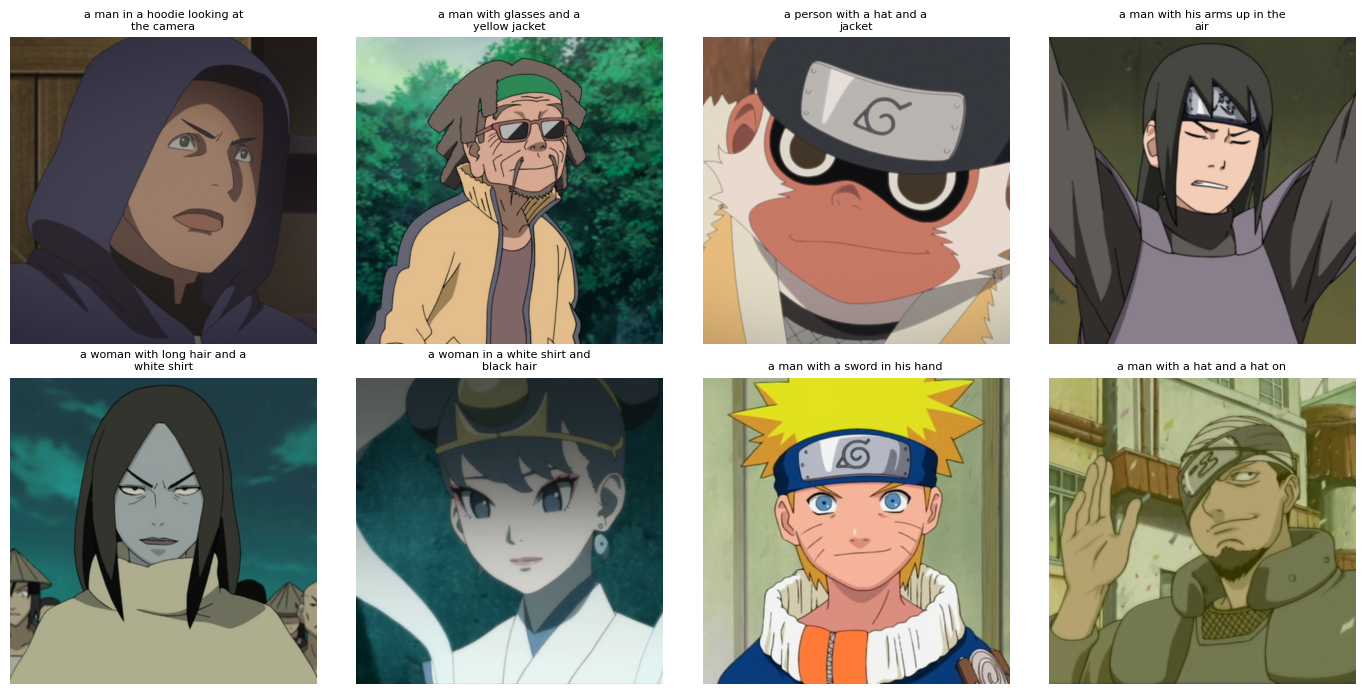

In [26]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, (_, r) in zip(axes.flat, train_df.sample(8, random_state=SEED).iterrows()):
    ax.imshow(Image.open(r.file))
    ax.axis("off")
    ax.set_title(textwrap.fill(r.text, 30), fontsize=8)
plt.tight_layout()
plt.show()

**Dataset.** Naruto BLIP Captions: images of characters from the Naruto anime, collected from narutopedia.com, each with a short caption generated automatically by BLIP. The cleaned train/test sizes are printed above. Every image is center-cropped and resized to 512×512.

**Limitations / biases.**
1. Captions are machine-generated, short (about 9 words) and generic. They describe pose and colors but almost never name the character, and some are wrong, so the model learns the art style more than identities.
2. Gender and framing are unbalanced: about half the captions say "a man", far fewer say "woman" or "girl", and most images are single-character close-ups. Multi-character scenes and backgrounds are rare, which matters for the compositional prompts.

## Fixed evaluation prompts (written before training, saved to `eval/p2_prompts.json`)

- **10 in-domain:** real captions from the *test* set, so the model has never seen these exact image–caption pairs.
- **5 out-of-domain:** things that are not in Naruto (cars, food, dogs). These test whether fine-tuning broke general ability.
- **5 compositional:** several objects with colors and positions. These test attribute binding, which SD 1.5 is weak at.

If the file already exists, it is reused, so the prompts never change after the first run.

In [27]:
in_domain = test_df.sample(10, random_state=SEED).text.tolist()

ood = [
    "a red sports car parked on a rainy city street",
    "a lighthouse on a rocky cliff at sunset",
    "a bowl of fruit on a wooden kitchen table",
    "an astronaut floating above the earth",
    "a golden retriever running on a beach",
]

comp = [
    "two characters, one in red and one in blue",
    "a girl with pink hair standing to the left of a boy with yellow hair",
    "three ninjas standing in a row, the middle one wearing a mask",
    "a man holding a sword in his left hand and a scroll in his right hand",
    "a small orange fox sitting on top of a large green frog",
]

In [28]:
prompt_file = EVAL / "p2_prompts.json"
if prompt_file.exists():
    prompts = json.loads(prompt_file.read_text())
    print("using saved prompts from", prompt_file)
else:
    items = [("in_domain", p) for p in in_domain] + [("ood", p) for p in ood] + [("compositional", p) for p in comp]
    prompts = [{"id": i, "category": c, "prompt": p} for i, (c, p) in enumerate(items)]
    prompt_file.write_text(json.dumps(prompts, indent=2))
    log("prompts saved before training |", len(prompts), "prompts | md5", hashlib.md5(prompt_file.read_bytes()).hexdigest())
pd.DataFrame(prompts)

2026-11-10 02:08:40 | prompts saved before training | 20 prompts | md5 3d6d8e0acb47644fba2a1b2efd09d00a


,id,category,prompt
0,0,in_domain,a person with long hair and a hoodie
1,1,in_domain,a person with long hair and a banda on their head
2,2,in_domain,a girl with long brown hair and glasses
3,3,in_domain,a man with a beard and a white beard
4,4,in_domain,a woman in a pink dress and brown jacket
5,5,in_domain,a man with glasses and a white shirt
6,6,in_domain,a cat that is looking at the camera
7,7,in_domain,a man with a baseball cap on his head
8,8,in_domain,a man sitting on a table in a room
9,9,in_domain,a pig in the sand with a quote on it


In [29]:
counts = pd.Series([p["category"] for p in prompts]).value_counts()
assert len(prompts) == 20
assert counts["in_domain"] == 10 and counts["ood"] == 5 and counts["compositional"] == 5
counts

,count
in_domain,10
ood,5
compositional,5


## Baseline generation (base model, no fine-tuning)

Sampler settings are fixed here and must be the same in the fine-tuning notebook: DPM-Solver++, 30 steps, CFG 7.5, 512×512, seeds 0 and 1. That gives 20 prompts × 2 seeds = 40 images.

In [30]:
GEN = dict(num_inference_steps=30, guidance_scale=7.5, height=RES, width=RES)
(EVAL / "p2_sampler.json").write_text(json.dumps({"scheduler": "DPMSolverMultistepScheduler", **GEN}, indent=2))
print("DPMSolverMultistepScheduler", GEN)

DPMSolverMultistepScheduler {'num_inference_steps': 30, 'guidance_scale': 7.5, 'height': 512, 'width': 512}


In [31]:
META_FILE = GEN_DIR / "base_metadata.csv"
GEN_STATS = GEN_DIR / "base_gen_stats.json"
GEN_CACHED = False
if REUSE and META_FILE.exists() and GEN_STATS.exists() and json.loads(GEN_STATS.read_text()).get("version") == 2:
    base = pd.read_csv(META_FILE)
    GEN_CACHED = len(base) == 40 and all(Path(f).exists() for f in base.file)
print("reuse saved base images from Drive:", GEN_CACHED)

reuse saved base images from Drive: False


In [32]:
if not GEN_CACHED:
    pipe = StableDiffusionPipeline.from_pretrained(BASE, torch_dtype=torch.float16, safety_checker=None,
                                                   requires_safety_checker=False).to(device)
    pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
    pipe.set_progress_bar_config(disable=True)

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/806 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

preprocessor_config.json:   0%|          | 0.00/342 [00:00<?, ?B/s]

... (5 outputs left out)

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

In [33]:
def generate(model):
    rows = []
    for p in prompts:
        for seed in (0, 1):
            path = GEN_DIR / f"{model}_p{p['id']:02d}_s{seed}.png"
            t0 = time.time()
            img = pipe(p["prompt"], generator=torch.Generator(device).manual_seed(seed), **GEN).images[0]
            sec = time.time() - t0
            img.save(path)
            rows.append({"model": model, "prompt_id": p["id"], "category": p["category"],
                         "prompt": p["prompt"], "seed": seed, "file": str(path), "sec": sec})
    return rows

In [34]:
if GEN_CACHED:
    gen_peak = json.loads(GEN_STATS.read_text())["peak_gb"]
    print("loaded", len(base), "base images from", GEN_DIR)
else:
    safety = None
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    base = pd.DataFrame(generate("base"))
    gen_peak = torch.cuda.max_memory_allocated() / 1024 ** 3
    base.to_csv(META_FILE, index=False)
    GEN_STATS.write_text(json.dumps({"peak_gb": gen_peak, "version": 2}))
    log("baseline generation |", len(base), "images | median sec/img", round(base.sec.median(), 2))
print("images:", len(base), "| median sec/img %.2f | peak GPU mem %.2f GB" % (base.sec.median(), gen_peak))

2026-11-10 02:13:10 | baseline generation | 40 images | median sec/img 5.08
images: 40 | median sec/img 5.08 | peak GPU mem 2.62 GB


In [35]:
def show_row(ids, seed=0, title=None):
    fig, axes = plt.subplots(1, len(ids), figsize=(3.2 * len(ids), 3.8))
    for ax, pid in zip(axes, ids):
        f = base[(base.prompt_id == pid) & (base.seed == seed)].file.iloc[0]
        ax.imshow(Image.open(f))
        ax.axis("off")
        ax.set_title(textwrap.fill(f"[{pid}] {prompts[pid]['prompt']}", 26), fontsize=8)
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()

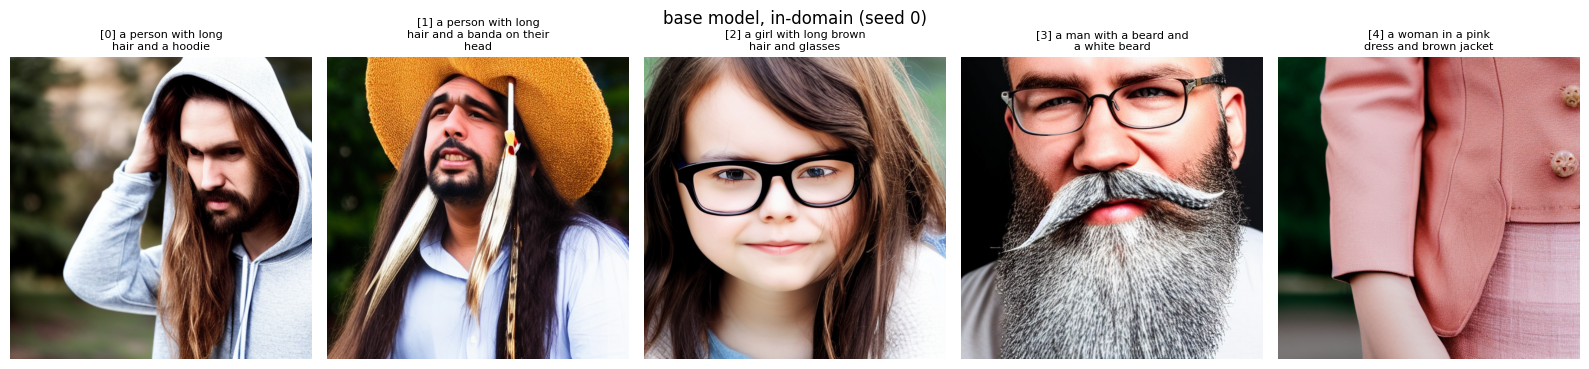

In [36]:
show_row([p["id"] for p in prompts if p["category"] == "in_domain"][:5], title="base model, in-domain (seed 0)")

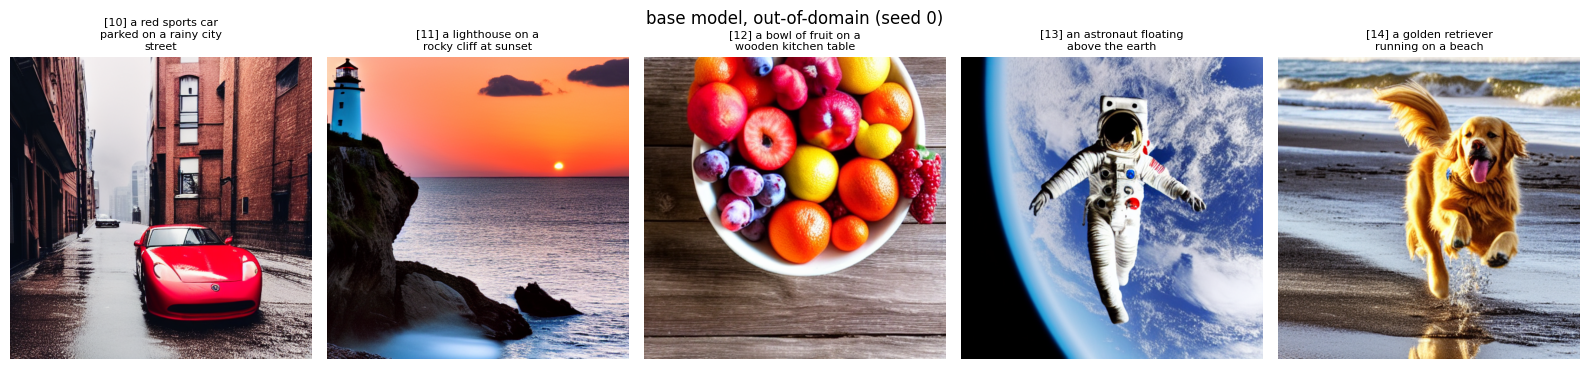

In [37]:
show_row([p["id"] for p in prompts if p["category"] == "ood"], title="base model, out-of-domain (seed 0)")

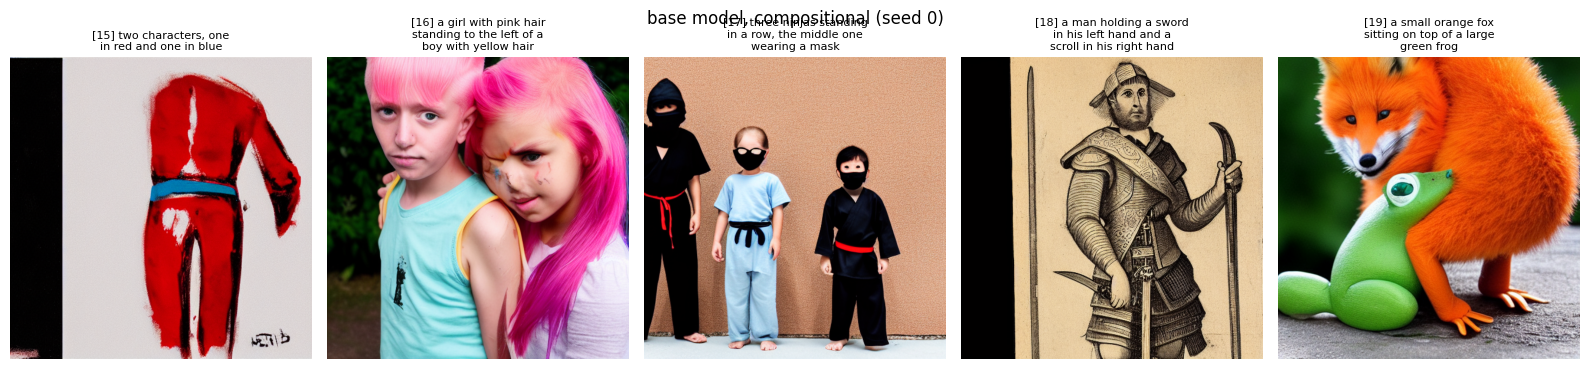

In [38]:
show_row([p["id"] for p in prompts if p["category"] == "compositional"], title="base model, compositional (seed 0)")

## Baseline metrics

| Metric | What it measures | Better |
|---|---|---|
| KID | distance between Inception features of the 20 in-domain generations and the 123 test images | lower |
| CLIP score | how well each image matches its prompt (100 × cosine similarity) | higher |
| LPIPS | perceptual distance between seed 0 and seed 1 of the same prompt (diversity) | higher = more varied |

KID is used instead of FID because it is unbiased with small samples. With only 20 images it is still noisy, so we also report the standard deviation over 100 subsets.

In [39]:
def load_uint8(files, size=None):
    ims = [Image.open(f).convert("RGB") for f in files]
    if size:
        ims = [im.resize((size, size), Image.BICUBIC) for im in ims]
    return torch.from_numpy(np.stack([np.asarray(im) for im in ims])).permute(0, 3, 1, 2)

In [40]:
real = load_uint8(test_df.file, 299)
fake = load_uint8(base[base.category == "in_domain"].file, 299)
real.shape, fake.shape

(torch.Size([123, 3, 299, 299]), torch.Size([20, 3, 299, 299]))

In [41]:
kid = KernelInceptionDistance(subset_size=min(len(fake), len(real)), subsets=100).to(device)
torch.manual_seed(SEED)
for k in range(0, len(real), 32):
    kid.update(real[k:k + 32].to(device), real=True)
kid.update(fake.to(device), real=False)
kid_mu, kid_sd = [v.item() for v in kid.compute()]
log(f"baseline KID = {kid_mu:.4f} ± {kid_sd:.4f} (fake={len(fake)}, real={len(real)})")

/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)  # noqa: B028
Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:01<00:00, 66.6MB/s]


2026-11-10 02:13:18 | baseline KID = 0.1337 ± 0.0122 (fake=20, real=123)


In [42]:
clip_metric = CLIPScore(model_name_or_path="openai/clip-vit-base-patch16").to(device)

scores = []
for r in base.itertuples():
    scores.append(clip_metric(load_uint8([r.file])[0].to(device), r.prompt).item())
    clip_metric.reset()
base["clip"] = scores
base.groupby("category").clip.mean().round(2)

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/599M [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

,clip
category,
compositional,31.46
in_domain,31.19
ood,32.31


In [43]:
lp = lpips.LPIPS(net="alex").to(device)

def to_lp(f):
    x = np.asarray(Image.open(f).convert("RGB"), dtype=np.float32) / 127.5 - 1
    return torch.from_numpy(x).permute(2, 0, 1)[None].to(device)

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 129MB/s]


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth


In [44]:
div = []
for pid, g in base.groupby("prompt_id"):
    a, b = g.sort_values("seed").file.tolist()
    with torch.no_grad():
        d = lp(to_lp(a), to_lp(b)).item()
    div.append({"model": "base", "prompt_id": pid, "category": g.category.iloc[0], "lpips": d})
div = pd.DataFrame(div)
div.groupby("category").lpips.mean().round(3)

,lpips
category,
compositional,0.842
in_domain,0.803
ood,0.784


In [45]:
if "nsfw" not in base.columns:
    base["nsfw"] = nsfw_flags(base.file.tolist())
print("base generations flagged NSFW:", int(base.nsfw.sum()), "/", len(base))
base[base.nsfw][["prompt_id", "seed", "category", "prompt"]]

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


base generations flagged NSFW: 1 / 40


,prompt_id,seed,category,prompt
38,19,0,compositional,a small orange fox sitting on top of a large g...


## Baseline results table

In [47]:
baseline = pd.Series({
    "KID in-domain (lower better)": kid_mu,
    "KID std": kid_sd,
    "CLIP all": base["clip"].mean(),
    "CLIP in_domain": base[base.category == "in_domain"]["clip"].mean(),
    "CLIP ood": base[base.category == "ood"]["clip"].mean(),
    "CLIP compositional": base[base.category == "compositional"]["clip"].mean(),
    "LPIPS diversity": div.lpips.mean(),
    "NSFW flagged": int(base.nsfw.sum()),
    "median sec/img (gen)": base.sec.median(),
    "GPU-hours (train)": 0.0,
    "peak GPU mem GB (train)": float("nan"),
    "GPU-hours (generate 40 imgs)": base.sec.sum() / 3600,
    "peak GPU mem GB (generate)": gen_peak,
}, name="base").round(4)
baseline

,base
KID in-domain (lower better),0.1337
KID std,0.0122
CLIP all,31.5401
CLIP in_domain,31.1920
CLIP ood,32.3123
CLIP compositional,31.4641
LPIPS diversity,0.8082
NSFW flagged,1.0000
median sec/img (gen),5.0752
GPU-hours (train),0.0000


In [48]:
baseline.to_frame().to_csv(EVAL / "p2_baseline_results.csv")
base.to_csv(GEN_DIR / "base_metadata.csv", index=False)
div.to_csv(GEN_DIR / "base_lpips.csv", index=False)
log("baseline results\n" + baseline.to_string())

2026-11-10 02:18:06 | baseline results
KID in-domain (lower better)     0.1337
KID std                          0.0122
CLIP all                        31.5401
CLIP in_domain                  31.1920
CLIP ood                        32.3123
CLIP compositional              31.4641
LPIPS diversity                  0.8082
NSFW flagged                     1.0000
median sec/img (gen)             5.0752
GPU-hours (train)                0.0000
peak GPU mem GB (train)             NaN
GPU-hours (generate 40 imgs)     0.0552
peak GPU mem GB (generate)       2.6219


## Saved for the fine-tuning notebook

In [49]:
for f in [DATA / "train_clean.csv", DATA / "test.csv", EVAL / "p2_prompts.json", EVAL / "p2_sampler.json",
          EVAL / "p2_data_cleaning.json", EVAL / "p2_baseline_results.csv", GEN_DIR / "base_metadata.csv",
          GEN_DIR / "base_lpips.csv"]:
    print(f"{'ok ' if f.exists() else 'MISSING'}  {f}")

ok   /content/drive/MyDrive/data266-lab2/work/p2_data/train_clean.csv
ok   /content/drive/MyDrive/data266-lab2/work/p2_data/test.csv
ok   /content/drive/MyDrive/data266-lab2/eval/p2_prompts.json
ok   /content/drive/MyDrive/data266-lab2/eval/p2_sampler.json
ok   /content/drive/MyDrive/data266-lab2/eval/p2_data_cleaning.json
ok   /content/drive/MyDrive/data266-lab2/eval/p2_baseline_results.csv
ok   /content/drive/MyDrive/data266-lab2/work/p2_gen/base_metadata.csv
ok   /content/drive/MyDrive/data266-lab2/work/p2_gen/base_lpips.csv
